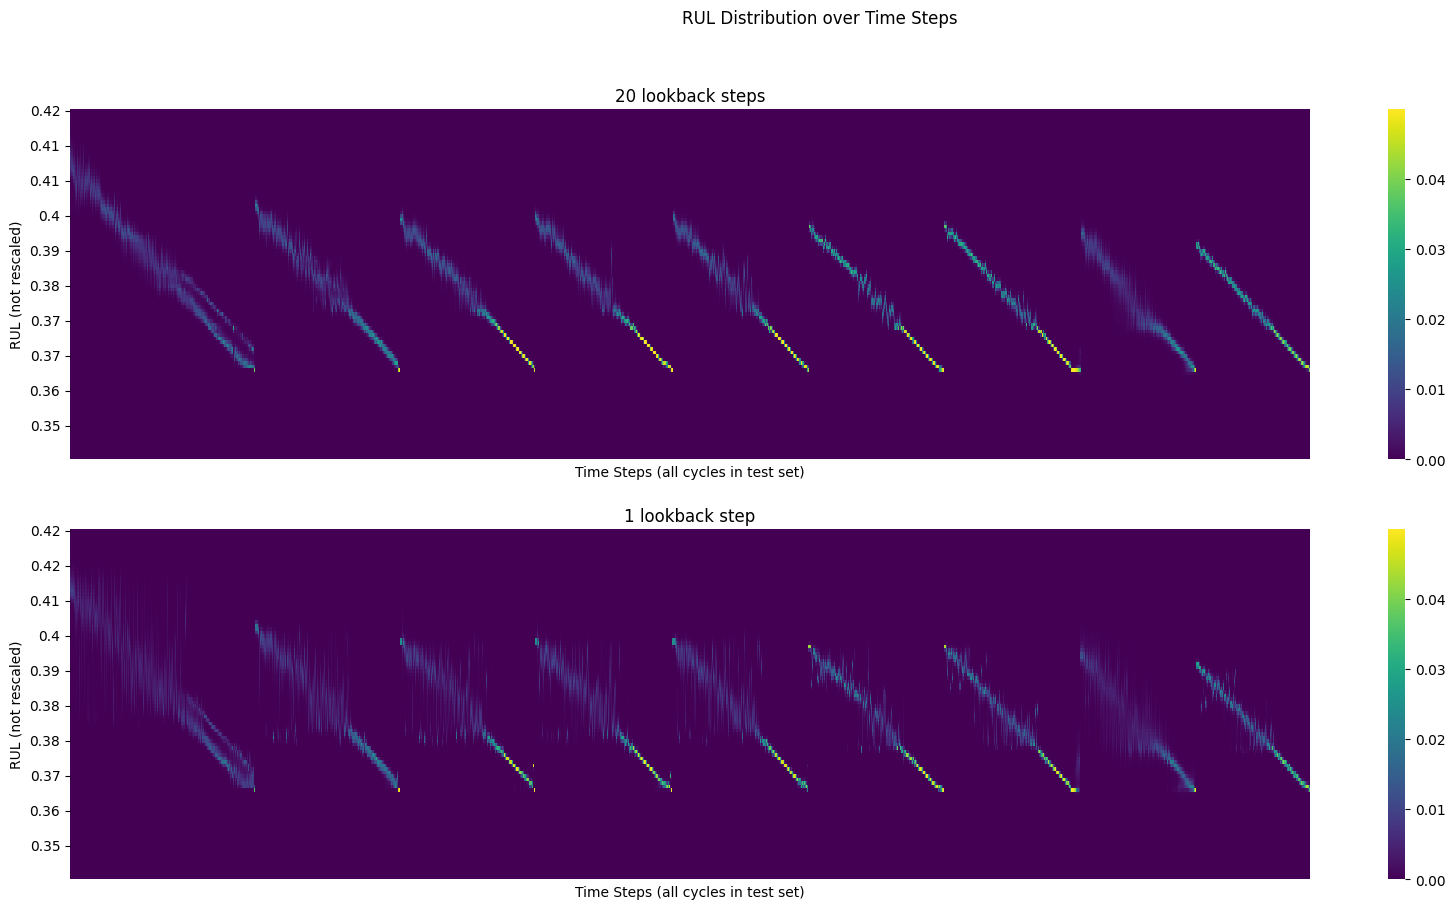

In [3]:
import seaborn as sns
import numpy as np
import torch
import hvplot.pandas  # noqa: F401
from pathlib import Path
import matplotlib.pyplot as plt


def plot_uc_to_axis(path, ax, title):
    t = torch.load(path, weights_only=False)
    t["criterion"].mean(t["logits"])
    borders = t["criterion"].borders
    bucket_means = borders[:-1] + t["criterion"].bucket_widths / 2
    bucket_means = bucket_means.cpu().numpy()

    p = torch.softmax(t["logits"], dim=-1)
    p = p.flip(1)
    bucket_means = bucket_means[::-1]

    low, high = 1500, 3500
    p = p[:, low:high]
    bucket_means = bucket_means[low:high]

    # Downsample the y-axis (bins) to 100 by interpolating or selecting evenly spaced bins
    num_bins = 100
    p_down = p.reshape(p.shape[0], -1, p.shape[1] // num_bins).mean(axis=2)
    bucket_means_down = bucket_means.reshape(-1, num_bins).mean(axis=0)

    sns.heatmap(
        p_down.T,
        yticklabels=np.round(bucket_means_down, 2),
        xticklabels=False,
        cmap="viridis",
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("Time Steps (all cycles in test set)")
    ax.set_ylabel("RUL (not rescaled)")

    # Reduce the number of y-axis labels
    max_labels = 10
    yticks = ax.get_yticks()
    if len(yticks) > max_labels:
        step = max(1, len(yticks) // max_labels)
        ax.set_yticks(yticks[::step])
        ax.set_yticklabels(np.round(bucket_means_down, 2)[::step])


fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(20, 10))

plot_uc_to_axis(Path(r"predictions_LB20.pt"), ax[0], "20 lookback steps")
plot_uc_to_axis(Path(r"predictions_LB1.pt"), ax[1], "1 lookback step")

fig.suptitle("RUL Distribution over Time Steps")
fig.savefig("picid_report_artifacts/phme20_rul_distribution_heatmap.png")

plt.show()